In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [2]:
df = pd.read_parquet("../data/processed/df_train.parquet")

In [3]:
df.columns

Index(['store_nbr', 'family', 'date', 'id', 'sales', 'onpromotion', 'weekday',
       'month', 'week', 'year', 'sales_missing', 'sales_lag15', 'sales_lag16',
       'sales_lag17', 'sales_lag18', 'sales_lag19', 'sales_lag20',
       'sales_lag30', 'sales_lag60', 'sales_lag90', 'sales_lag364',
       'sales_lag365', 'is_int_sales', 'city', 'state', 'store_type',
       'store_cluster', 'locale_name', 'is_holiday', 'is_pre_holiday',
       'dcoilwtico', 'transactions'],
      dtype='str')

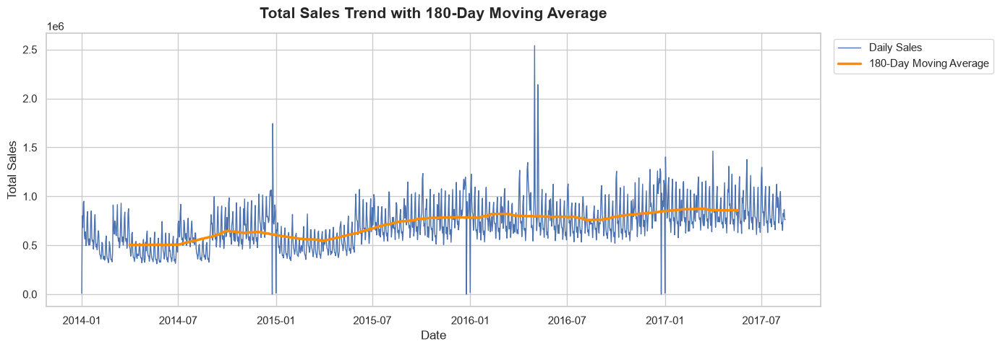

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Preparar los datos
df_toplot = df.groupby("date")["sales"].sum().reset_index()
df_toplot["date"] = pd.to_datetime(df_toplot["date"])

# 2. Calcular la Media Móvil (180 días)
# center=True centra el cálculo para que la línea no esté desfasada temporalmente
df_toplot["rolling_mean"] = df_toplot["sales"].rolling(window=180, center=True).mean()

# 3. Configuración del gráfico
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 5))

# Capa A: Datos Diarios (Ruido) - Finos y transparentes
plt.plot(df_toplot["date"], df_toplot["sales"], linewidth=1, label="Daily Sales")

# Capa B: Media Móvil (Tendencia Estructural) - Gruesa y contrastante
plt.plot(
    df_toplot["date"],
    df_toplot["rolling_mean"],
    color="darkorange",
    linewidth=2.5,
    label="180-Day Moving Average",
)

# 4. Estética
plt.title(
    "Total Sales Trend with 180-Day Moving Average",
    fontsize=15,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Total Sales", fontsize=12)

plt.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

In [30]:
coords_data = {
    "city": [
        "Quito",
        "Santo Domingo",
        "Cayambe",
        "Latacunga",
        "Riobamba",
        "Ibarra",
        "Guaranda",
        "Puyo",
        "Ambato",
        "Guayaquil",
        "Salinas",
        "Daule",
        "Babahoyo",
        "Quevedo",
        "Playas",
        "Libertad",
        "Cuenca",
        "Loja",
        "Machala",
        "Esmeraldas",
        "Manta",
        "El Carmen",
    ],
    "lat": [
        -0.2298,
        -0.2530,
        0.0428,
        -0.9315,
        -1.6635,
        0.3517,
        -1.5904,
        -1.4836,
        -1.2490,
        -2.1894,
        -2.2145,
        -1.8621,
        -1.8021,
        -1.0286,
        -2.6284,
        -2.2330,
        -2.9001,
        -3.9931,
        -3.2581,
        0.9592,
        -0.9676,
        -0.2713,
    ],
    "lon": [
        -78.5249,
        -79.1753,
        -78.1452,
        -78.6158,
        -78.6546,
        -78.1223,
        -79.0022,
        -77.9950,
        -78.6167,
        -79.8890,
        -80.9515,
        -79.9776,
        -79.5344,
        -79.4635,
        -80.3895,
        -80.9103,
        -79.0058,
        -79.2042,
        -79.9553,
        -79.6539,
        -80.7089,
        -79.4647,
    ],
}

df_coords = pd.DataFrame(coords_data)

df_agg = df.groupby(["city"])["sales"].sum().reset_index()
df_toplot = pd.merge(df_agg, df_coords, on="city", how="left")

fig = px.scatter_map(
    df_toplot,
    lat="lat",
    lon="lon",
    size="sales",
    hover_name="city",
    hover_data={"lat": False, "lon": False},
    size_max=40,
    zoom=5.5,
    center={"lat": -1.8312, "lon": -78.1834},
    map_style="carto-positron",
)

fig.show(config={"staticPlot": False})

In [6]:
df_agg.sort_values("sales", ascending=False)

df_agg[(df_agg["city"] == "Quito")]["sales"].sum() / df_agg["sales"].sum()

np.float64(0.5187605792412208)

More than fifty percent of sales took place in Quito. 

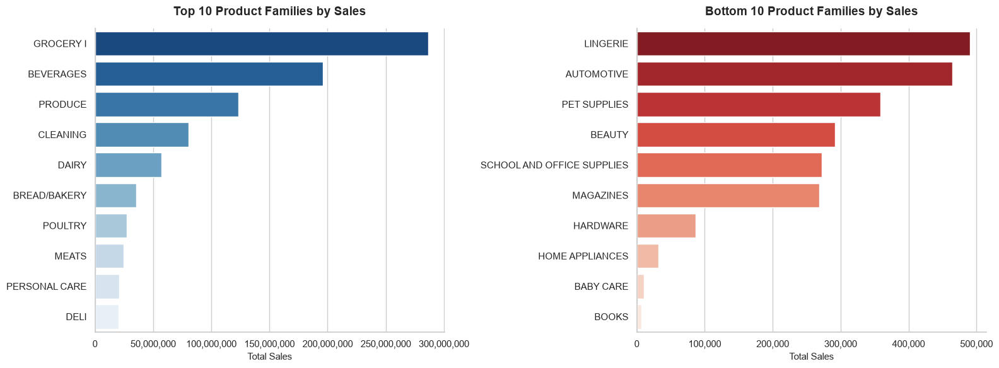

In [7]:
df_family = (
    df.groupby(["family"])["sales"]
    .sum()
    .reset_index()
    .sort_values("sales", ascending=False)
)
top_10 = df_family.head(10)
bottom_10 = df_family.tail(10)

sns.set_theme(style="whitegrid")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(
    data=top_10,
    x="sales",
    y="family",
    ax=ax1,
    hue="family",
    legend=False,
    palette="Blues_r",
)
ax1.set_title(
    "Top 10 Product Families by Sales", fontsize=14, fontweight="bold", pad=15
)
ax1.set_xlabel("Total Sales", fontsize=11)
ax1.set_ylabel("")

sns.barplot(
    data=bottom_10,
    x="sales",
    y="family",
    ax=ax2,
    hue="family",
    legend=False,
    palette="Reds_r",
)
ax2.set_title(
    "Bottom 10 Product Families by Sales", fontsize=14, fontweight="bold", pad=15
)
ax2.set_xlabel("Total Sales", fontsize=11)
ax2.set_ylabel("")

for ax in [ax1, ax2]:
    ax.xaxis.set_major_formatter(
        plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x)))
    )
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

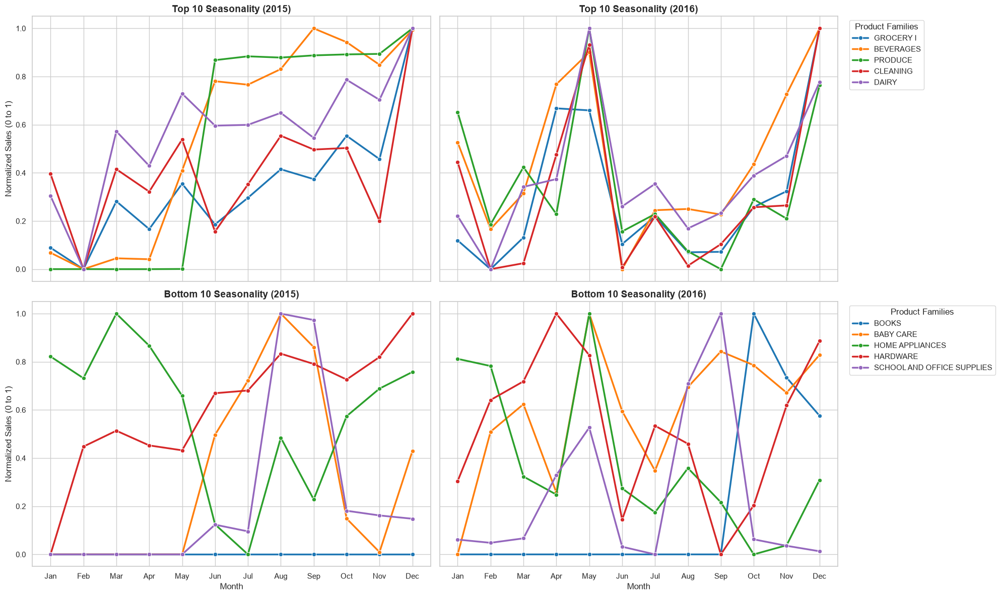

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Define the years to analyze
target_year = 2016
previous_year = target_year - 1

# Filter data for both years
df_years = df[df["year"].isin([previous_year, target_year])].copy()

# 2. Identify Top 10 and Bottom 10 families based on the TARGET year (2016)
yearly_totals_target = (
    df_years[df_years["year"] == target_year]
    .groupby("family")["sales"]
    .sum()
    .reset_index()
)
top_10_fams = yearly_totals_target.nlargest(5, "sales")["family"].tolist()
bottom_10_fams = yearly_totals_target.nsmallest(5, "sales")["family"].tolist()

# 3. Aggregate sales by Year, Family, and Month
monthly_sales = (
    df_years.groupby(["year", "family", "month"])["sales"].sum().reset_index()
)


# 4. Normalize (Min-Max Scaling per family WITHIN each year)
# 0 = worst month of the year, 1 = best month of the year
def min_max_scale(x):
    if x.max() == x.min():
        return x * 0  # Handles division by zero if sales are completely flat
    return (x - x.min()) / (x.max() - x.min())


monthly_sales["sales_normalized"] = monthly_sales.groupby(["year", "family"])[
    "sales"
].transform(min_max_scale)

# 5. Split datasets
top_10_monthly = monthly_sales[monthly_sales["family"].isin(top_10_fams)]
bottom_10_monthly = monthly_sales[monthly_sales["family"].isin(bottom_10_fams)]

# 6. Plotting setup: 2 rows (Top/Bottom), 2 columns (Previous/Target Year)
sns.set_theme(style="whitegrid")
# sharey=True is now perfect because all 4 plots strictly range from 0 to 1
fig, axes = plt.subplots(2, 2, figsize=(20, 12), sharex=True, sharey=True)
months_labels = [
    "Jan",
    "Feb",
    "Mar",
    "Apr",
    "May",
    "Jun",
    "Jul",
    "Aug",
    "Sep",
    "Oct",
    "Nov",
    "Dec",
]


# Helper function to plot each subplot cleanly
def plot_seasonality(ax, data, year, order, title, is_bottom_row):
    sns.lineplot(
        data=data[data["year"] == year],
        x="month",
        y="sales_normalized",
        hue="family",
        hue_order=order,
        marker="o",
        linewidth=2.5,
        ax=ax,
        palette="tab10",
    )
    ax.set_title(f"{title} ({year})", fontsize=14, fontweight="bold")

    # Y-axis label only on the left column
    if ax.get_subplotspec().is_first_col():
        ax.set_ylabel("Normalized Sales (0 to 1)", fontsize=12)
    else:
        ax.set_ylabel("")

    # X-axis label and ticks only on the bottom row
    if is_bottom_row:
        ax.set_xlabel("Month", fontsize=12)
        ax.set_xticks(range(1, 13))
        ax.set_xticklabels(months_labels)

    # Legend only on the right column to avoid clutter
    if ax.get_subplotspec().is_last_col():
        ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Product Families")
    else:
        if ax.get_legend():
            ax.get_legend().remove()


# --- Render the 4 subplots ---
# Row 0: Top 10 (Left: 2015, Right: 2016)
plot_seasonality(
    axes[0, 0], top_10_monthly, previous_year, top_10_fams, "Top 10 Seasonality", False
)
plot_seasonality(
    axes[0, 1], top_10_monthly, target_year, top_10_fams, "Top 10 Seasonality", False
)

# Row 1: Bottom 10 (Left: 2015, Right: 2016)
plot_seasonality(
    axes[1, 0],
    bottom_10_monthly,
    previous_year,
    bottom_10_fams,
    "Bottom 10 Seasonality",
    True,
)
plot_seasonality(
    axes[1, 1],
    bottom_10_monthly,
    target_year,
    bottom_10_fams,
    "Bottom 10 Seasonality",
    True,
)

plt.tight_layout()
plt.show()

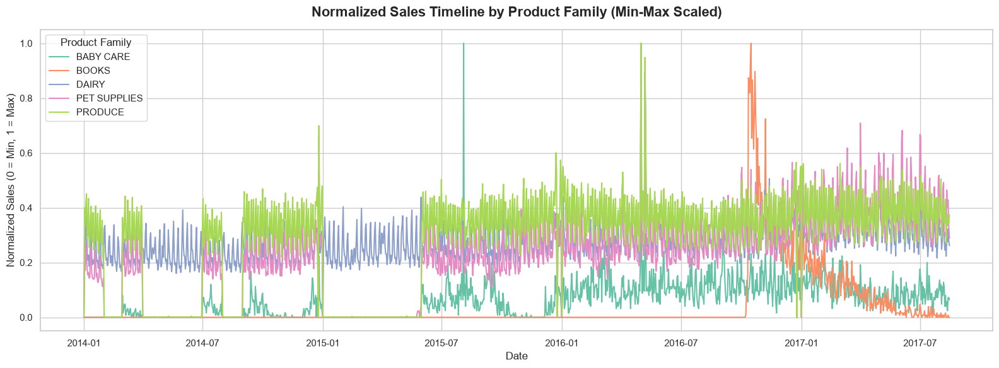

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Filtrar y agrupar por fecha y familia
target_fams = ["BOOKS", "PRODUCE", "PET SUPPLIES", "BABY CARE", "DAIRY"]
df_filtered = df[df["family"].isin(target_fams)]
df_timeline = df_filtered.groupby(["date", "family"])["sales"].sum().reset_index()

# 2. NORMALIZACIÓN: Min-Max Scaling por familia (escala de 0 a 1)
# Así, el pico máximo de cada familia tocará el 1.0 en el eje Y
df_timeline["sales_normalized"] = df_timeline.groupby("family")["sales"].transform(
    lambda x: (x - x.min()) / (x.max() - x.min())
)

# 3. Configurar y dibujar el gráfico
sns.set_theme(style="whitegrid")
plt.figure(figsize=(16, 6))

sns.lineplot(
    data=df_timeline,
    x="date",
    y="sales_normalized",
    hue="family",
    linewidth=1.5,  # Un poco más fino para que las líneas no se tapen tanto
    palette="Set2",
)

# 4. Detalles estéticos en inglés
plt.title(
    "Normalized Sales Timeline by Product Family (Min-Max Scaled)",
    fontsize=16,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Normalized Sales (0 = Min, 1 = Max)", fontsize=12)
plt.legend(title="Product Family", loc="upper left")

plt.tight_layout()
plt.show()

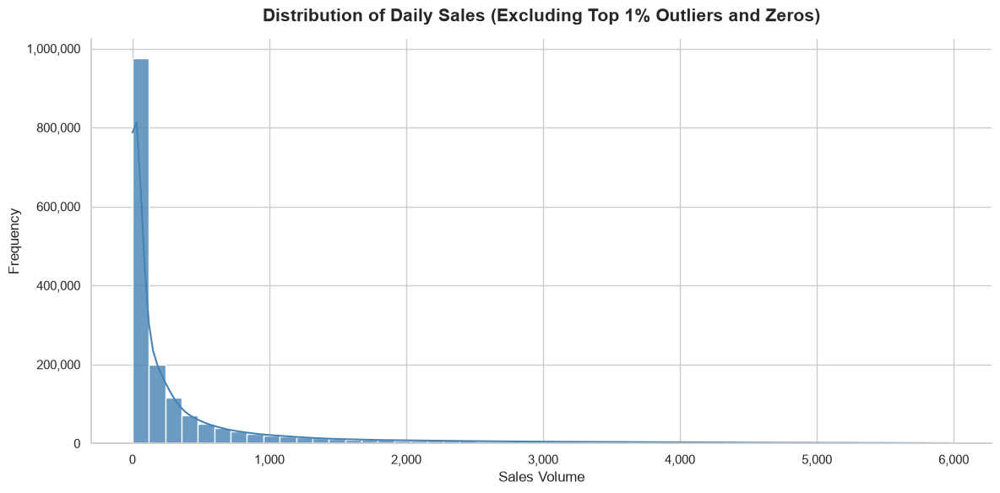

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. FILTRAR DATOS: Ignorar ceros y cortar en el percentil 95
# Esto revela la verdadera distribución del día a día normal
upper_limit = df["sales"].quantile(0.99)
df_plot = df[(df["sales"] > 0) & (df["sales"] <= upper_limit)]

# 2. Configuración general
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

sns.histplot(
    data=df_plot,
    x="sales",
    bins=50,
    kde=True,
    color="steelblue",
    edgecolor="white",
    alpha=0.8,
)

# 3. Estética
# Añadimos en el título que es la distribución del 95% de los datos para ser precisos
plt.title(
    "Distribution of Daily Sales (Excluding Top 1% Outliers and Zeros)",
    fontsize=15,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Sales Volume", fontsize=12)
plt.ylabel("Frequency", fontsize=12)

# Formatear ejes
plt.gca().xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x)))
)
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, loc: "{:,}".format(int(y)))
)

sns.despine()
plt.tight_layout()
plt.show()

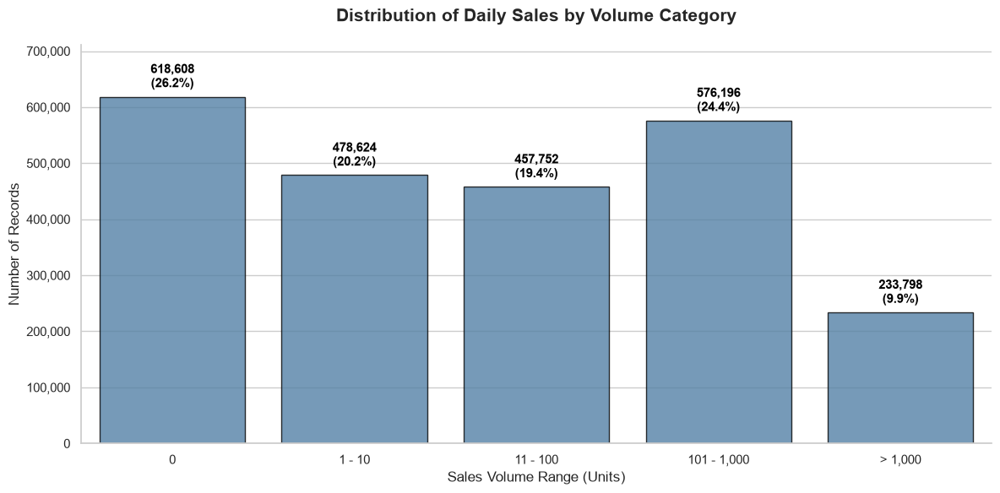

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Definir los límites de los grupos (bins) y sus nombres
# pd.cut incluye el valor de la derecha por defecto (ej. de 0 a 10 incluye el 10)
bins = [-1, 0, 10, 100, 1000, np.inf]
etiquetas = ["0", "1 - 10", "11 - 100", "101 - 1,000", "> 1,000"]

# 2. Crear la nueva columna categórica
df["sales_bucket"] = pd.cut(df["sales"], bins=bins, labels=etiquetas)

# 3. Contar la frecuencia de cada grupo
df_buckets = df["sales_bucket"].value_counts().reset_index()
df_buckets.columns = ["Bucket", "Count"]

# Asegurar que se grafiquen en el orden correcto
df_buckets["Bucket"] = pd.Categorical(
    df_buckets["Bucket"], categories=etiquetas, ordered=True
)
df_buckets = df_buckets.sort_values("Bucket")

# 4. Configurar y dibujar el gráfico
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

# Usamos barplot porque el eje X ahora son categorías de texto
ax = sns.barplot(
    data=df_buckets,
    x="Bucket",
    y="Count",
    color="steelblue",
    edgecolor="black",
    alpha=0.8,
)

# 5. Añadir el número total y el % encima de cada barra (Súper pro para portfolios)
total_records = len(df)
for p in ax.patches:
    height = p.get_height()
    if height > 0:  # Para evitar errores si un bucket está vacío
        porcentaje = (height / total_records) * 100
        # Escribe el texto: "Ej: 15,000 \n (32.5%)"
        ax.annotate(
            f"{int(height):,}\n({porcentaje:.1f}%)",
            (p.get_x() + p.get_width() / 2.0, height),
            ha="center",
            va="bottom",
            fontsize=11,
            fontweight="bold",
            color="black",
            xytext=(0, 5),
            textcoords="offset points",
        )

# 6. Estética final (Inglés)
plt.title(
    "Distribution of Daily Sales by Volume Category",
    fontsize=15,
    fontweight="bold",
    pad=20,
)
plt.xlabel("Sales Volume Range (Units)", fontsize=12)
plt.ylabel("Number of Records", fontsize=12)

# Formatear eje Y con comas
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, loc: "{:,}".format(int(y))))

# Eliminar líneas extra del recuadro
sns.despine()

# Ampliar margen superior para que los textos de las barras no se corten
plt.margins(y=0.15)
plt.tight_layout()
plt.show()

In [12]:
df.columns

Index(['store_nbr', 'family', 'date', 'id', 'sales', 'onpromotion', 'weekday',
       'month', 'week', 'year', 'sales_missing', 'sales_lag15', 'sales_lag16',
       'sales_lag17', 'sales_lag18', 'sales_lag19', 'sales_lag20',
       'sales_lag30', 'sales_lag60', 'sales_lag90', 'sales_lag364',
       'sales_lag365', 'is_int_sales', 'city', 'state', 'store_type',
       'store_cluster', 'locale_name', 'is_holiday', 'is_pre_holiday',
       'dcoilwtico', 'transactions', 'sales_bucket'],
      dtype='str')

In [13]:
df.groupby("store_type")["sales"].sum().reset_index().sort_values(
    "sales", ascending=False
)

,store_type,sales
0,A,3.074029e+08
3,D,3.065988e+08
2,C,1.415505e+08
1,B,1.273638e+08
4,E,5.442438e+07


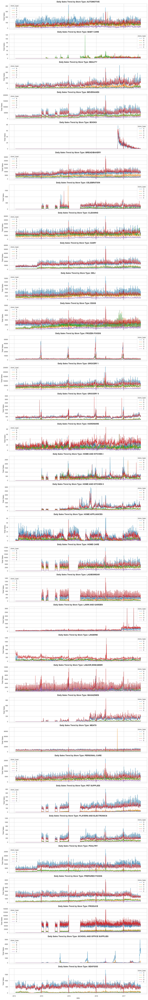

In [122]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

target_families = ["AUTOMOTIVE", "LADIESWEAR", "PRODUCE"]
target_families = df["family"].unique()
df_filtered = df[df["family"].isin(target_families)].copy()

df_agg = (
    df_filtered.groupby(["family", "date", "store_type"])["sales"].sum().reset_index()
)
df_agg["date"] = pd.to_datetime(df_agg["date"])

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(33, 1, figsize=(15, 100), sharex=True)

for i, family in enumerate(target_families):
    sns.lineplot(
        data=df_agg[df_agg["family"] == family],
        x="date",
        y="sales",
        hue="store_type",
        linewidth=1,
        palette="tab10",
        ax=axes[i],
    )

    axes[i].set_title(
        f"Daily Sales Trend by Store Type: {family}",
        fontsize=14,
        fontweight="bold",
        pad=10,
    )
    axes[i].set_ylabel("Total Sales", fontsize=12)


plt.tight_layout()
plt.show()

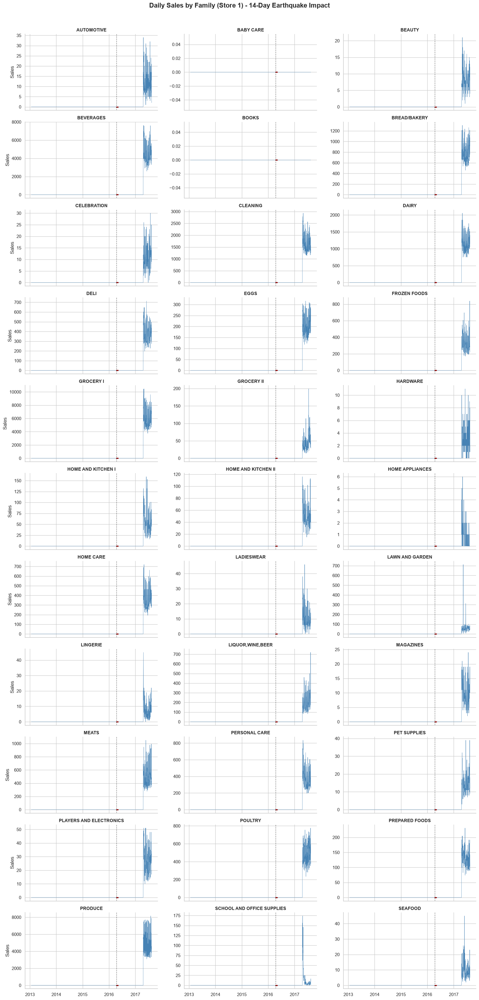

In [123]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

df_store1 = df[df["store_nbr"] == 52].copy()
df_agg = df_store1.groupby(["family", "date"])["sales"].sum().reset_index()

sns.set_theme(style="whitegrid")
g = sns.FacetGrid(df_agg, col="family", col_wrap=3, sharey=False, height=3, aspect=1.8)


def plot_impact_window(data, **kwargs):
    ax = plt.gca()

    sns.lineplot(
        data=data, x="date", y="sales", color="steelblue", linewidth=0.5, ax=ax
    )

    impact_data = data[(data["date"] >= "2016-04-16") & (data["date"] <= "2016-05-07")]

    if not impact_data.empty:
        sns.lineplot(
            data=impact_data, x="date", y="sales", color="darkred", linewidth=2.5, ax=ax
        )

    ax.axvline(
        pd.to_datetime("2016-04-16"),
        color="black",
        linestyle="--",
        alpha=0.5,
        linewidth=1,
    )


g.map_dataframe(plot_impact_window)

g.fig.suptitle(
    "Daily Sales by Family (Store 1) - 14-Day Earthquake Impact",
    y=1.02,
    fontsize=16,
    fontweight="bold",
)
g.set_titles("{col_name}", fontweight="bold", size=11)
g.set_axis_labels("", "Sales")

plt.show()

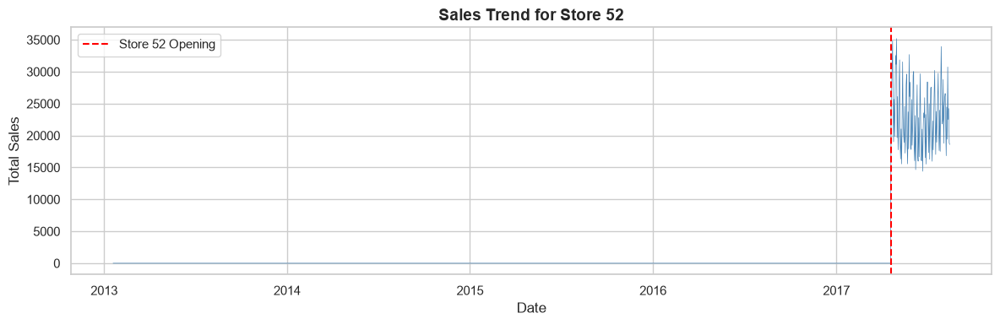

In [124]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Agrupar los datos
data = df[df["store_nbr"] == 52].groupby(["date"])["sales"].sum().reset_index()

# 3. Dibujar el gráfico
plt.figure(figsize=(12, 4))
sns.lineplot(data=data, x="date", y="sales", color="steelblue", linewidth=0.5)

# Opcional: Destacar visualmente cuándo abrió realmente la tienda
plt.axvline(
    pd.to_datetime("2017-04-20"), color="red", linestyle="--", label="Store 52 Opening"
)

plt.title("Sales Trend for Store 52", fontsize=14, fontweight="bold")
plt.xlabel("Date", fontsize=12)
plt.ylabel("Total Sales", fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

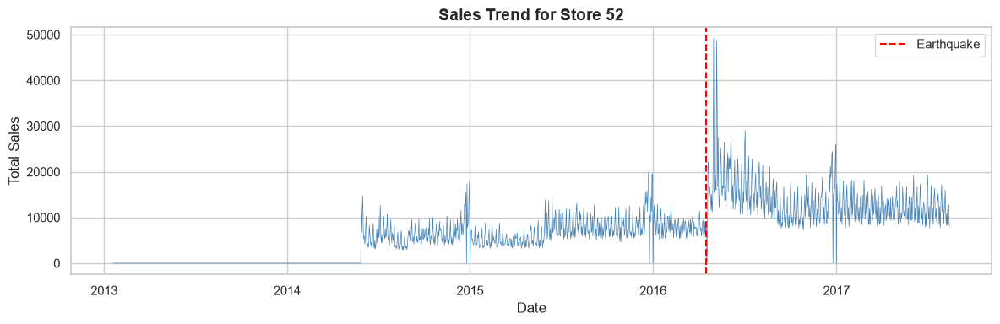

           date         sales
1181 2016-04-14   6510.128000
1182 2016-04-15   7630.432996
1183 2016-04-16   8206.027100
1184 2016-04-17    257.190000
1185 2016-04-18    279.728000
1186 2016-04-19  12263.964100
1187 2016-04-20  22151.527000
1188 2016-04-21  21954.989000
1189 2016-04-22  14776.463000
1190 2016-04-23  16712.148000


In [125]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Agrupar los datos
data = df[df["store_nbr"] == 53].groupby(["date"])["sales"].sum().reset_index()

# 3. Dibujar el gráfico
plt.figure(figsize=(12, 4))
sns.lineplot(data=data, x="date", y="sales", color="steelblue", linewidth=0.5)

# Opcional: Destacar visualmente cuándo abrió realmente la tienda
plt.axvline(
    pd.to_datetime("2016-04-16"), color="red", linestyle="--", label="Earthquake"
)

plt.title("Sales Trend for Store 52", fontsize=14, fontweight="bold")
plt.xlabel("Date", fontsize=12)
plt.ylabel("Total Sales", fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

print(data[data["date"] >= "2016-04-14"].head(10))

In [ ]:
# Fue en este lugar el terremoto a las 19h del dia 16 de abril de 2016.

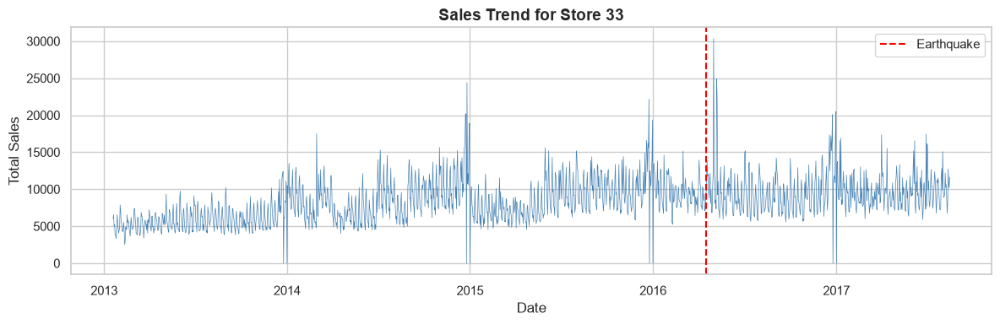

In [126]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Store 33, close to the earthquake epicenter but far enough
data = df[df["store_nbr"] == 33].groupby(["date"])["sales"].sum().reset_index()

plt.figure(figsize=(12, 4))
sns.lineplot(data=data, x="date", y="sales", color="steelblue", linewidth=0.5)

plt.axvline(
    pd.to_datetime("2016-04-16"), color="red", linestyle="--", label="Earthquake"
)

plt.title("Sales Trend for Store 33", fontsize=14, fontweight="bold")
plt.xlabel("Date", fontsize=12)
plt.ylabel("Total Sales", fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

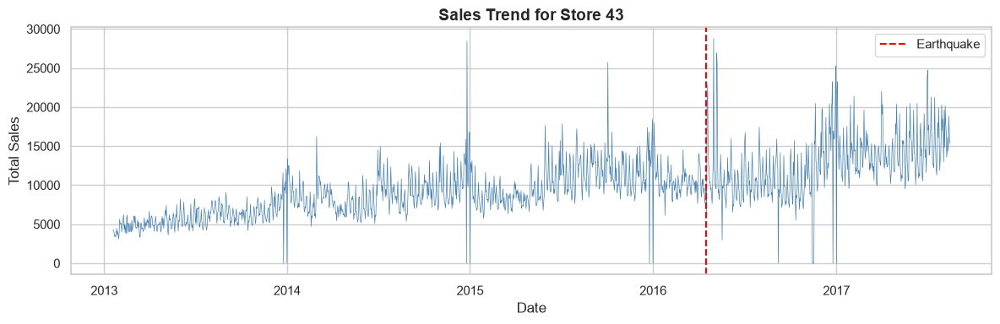

           date         sales
1181 2016-04-14   7703.476000
1182 2016-04-15   9353.198000
1183 2016-04-16   9499.975000
1184 2016-04-17   6568.407996
1185 2016-04-18  20648.833000
1186 2016-04-19  22903.889010
1187 2016-04-20  15200.772000
1188 2016-04-21  12605.690000
1189 2016-04-22  11768.859000
1190 2016-04-23  10272.015000


In [127]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Store 33, close to the earthquake epicenter
data = df[df["store_nbr"] == 43].groupby(["date"])["sales"].sum().reset_index()

plt.figure(figsize=(12, 4))
sns.lineplot(data=data, x="date", y="sales", color="steelblue", linewidth=0.5)

plt.axvline(
    pd.to_datetime("2016-04-16"), color="red", linestyle="--", label="Earthquake"
)

plt.title("Sales Trend for Store 43", fontsize=14, fontweight="bold")
plt.xlabel("Date", fontsize=12)
plt.ylabel("Total Sales", fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

print(data[data["date"] >= "2016-04-14"].head(10))

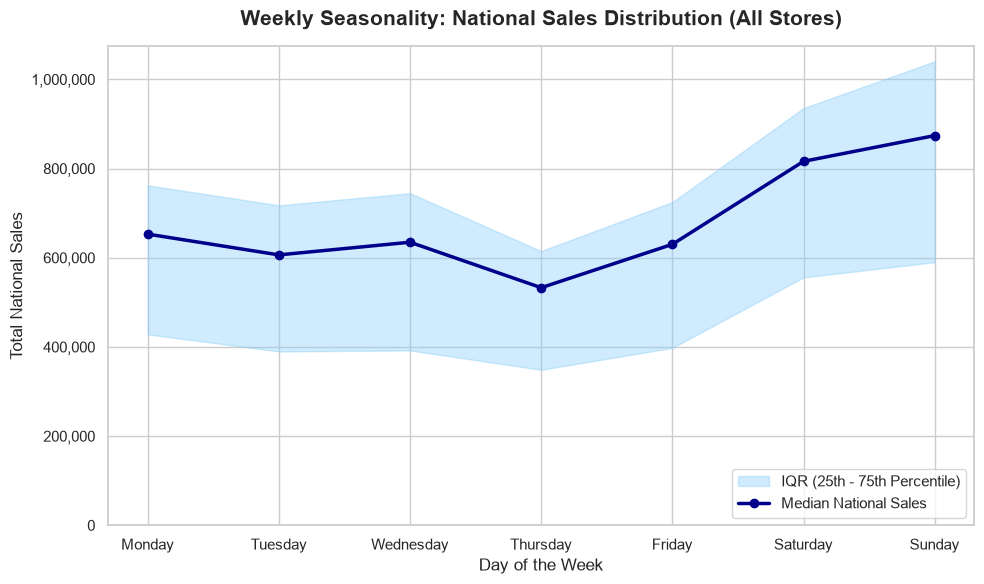

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_daily_total = df.groupby(["date", "weekday"])["sales"].sum().reset_index()

weekly_stats = (
    df_daily_total.groupby("weekday")["sales"]
    .agg(
        median="median", q25=lambda x: x.quantile(0.25), q75=lambda x: x.quantile(0.75)
    )
    .reset_index()
)

days_map = {
    0: "Monday",
    1: "Tuesday",
    2: "Wednesday",
    3: "Thursday",
    4: "Friday",
    5: "Saturday",
    6: "Sunday",
}
weekly_stats["weekday_name"] = weekly_stats["weekday"].map(days_map)

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

plt.fill_between(
    weekly_stats["weekday_name"],
    weekly_stats["q25"],
    weekly_stats["q75"],
    color="lightskyblue",
    alpha=0.4,
    label="IQR (25th - 75th Percentile)",
)

plt.plot(
    weekly_stats["weekday_name"],
    weekly_stats["median"],
    color="darkblue",
    linewidth=2.5,
    marker="o",
    markersize=6,
    label="Median National Sales",
)

plt.title(
    "Weekly Seasonality: National Sales Distribution (All Stores)",
    fontsize=15,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Day of the Week", fontsize=12)
plt.ylabel("Total National Sales", fontsize=12)

plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x)))
)
plt.ylim(bottom=0)

plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [213]:
df_daily_total["sales"].median()

np.float64(8.0)

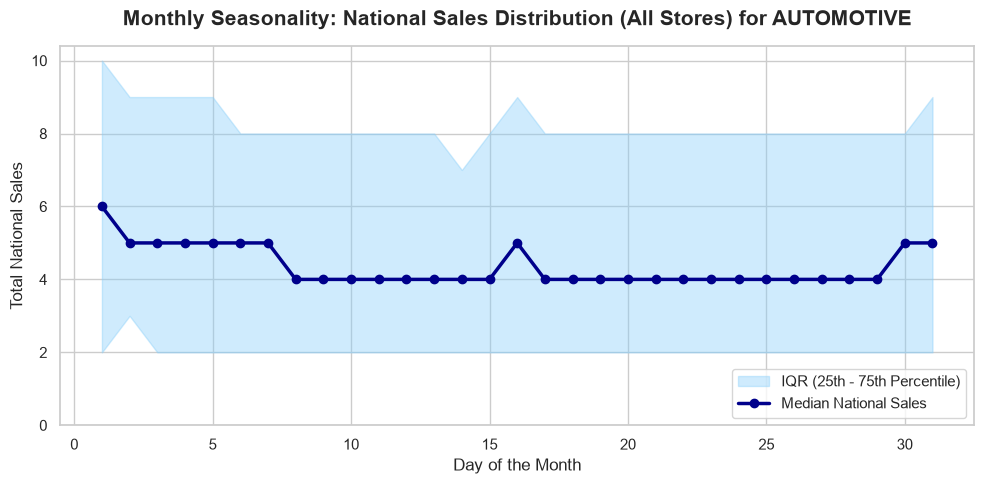

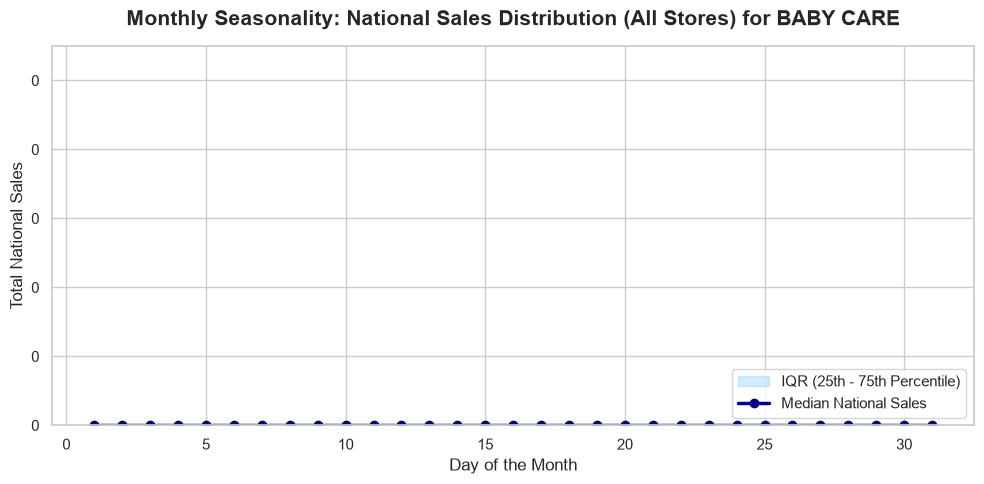

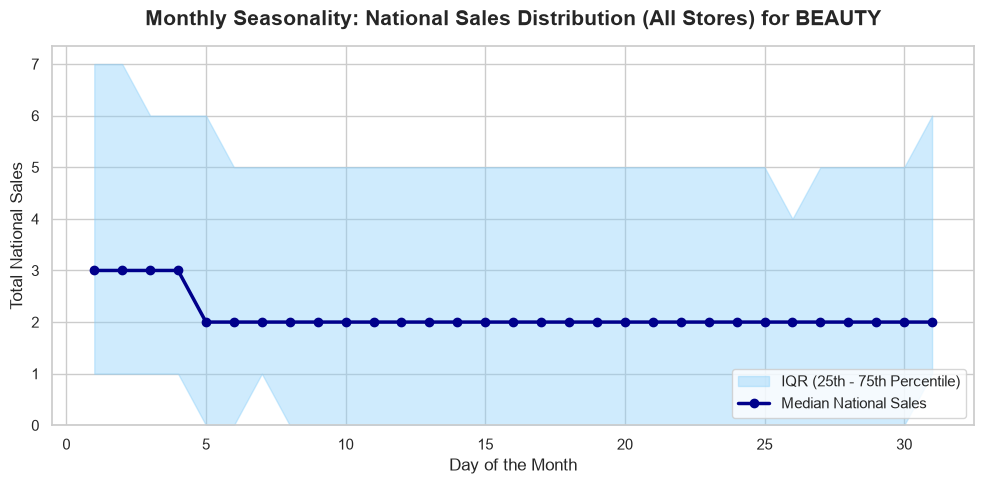

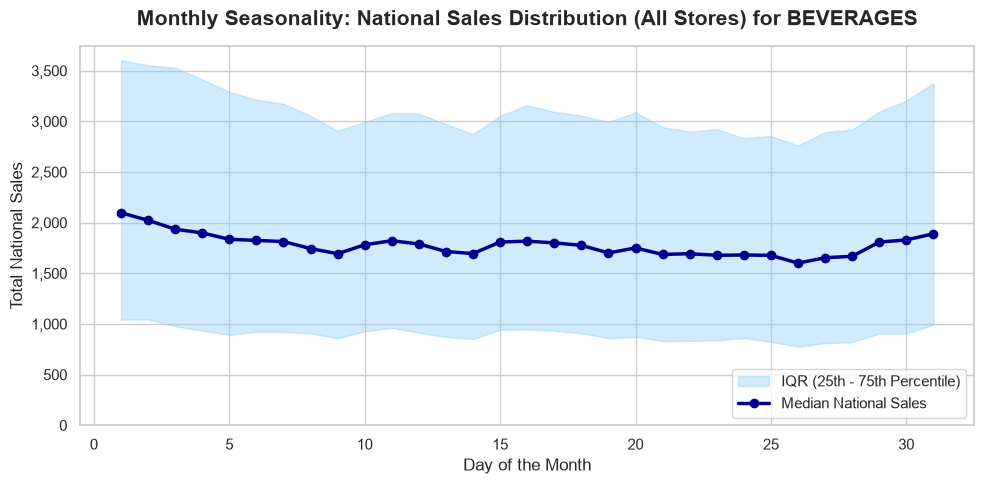

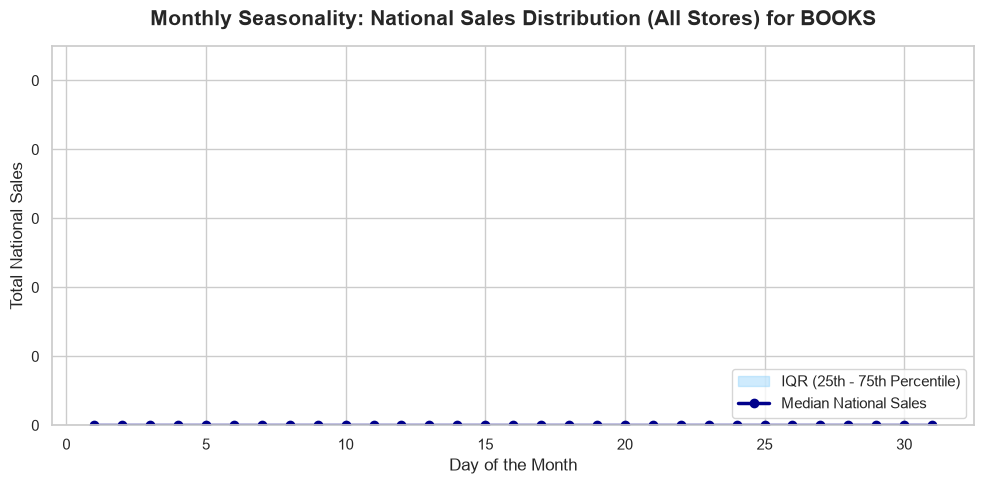

...

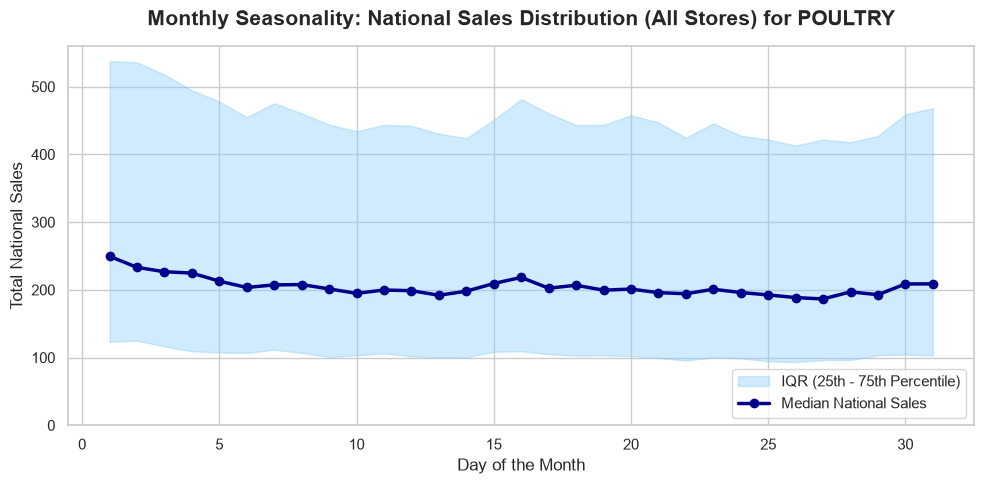

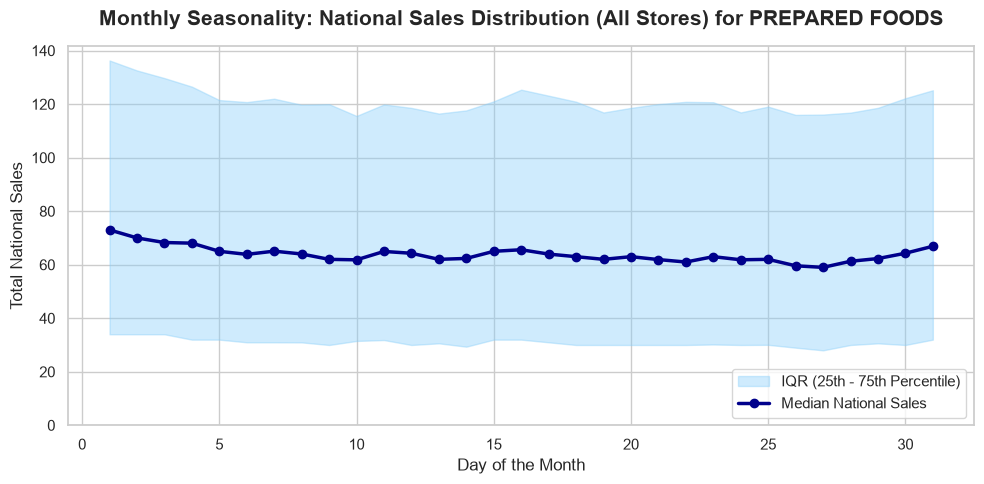

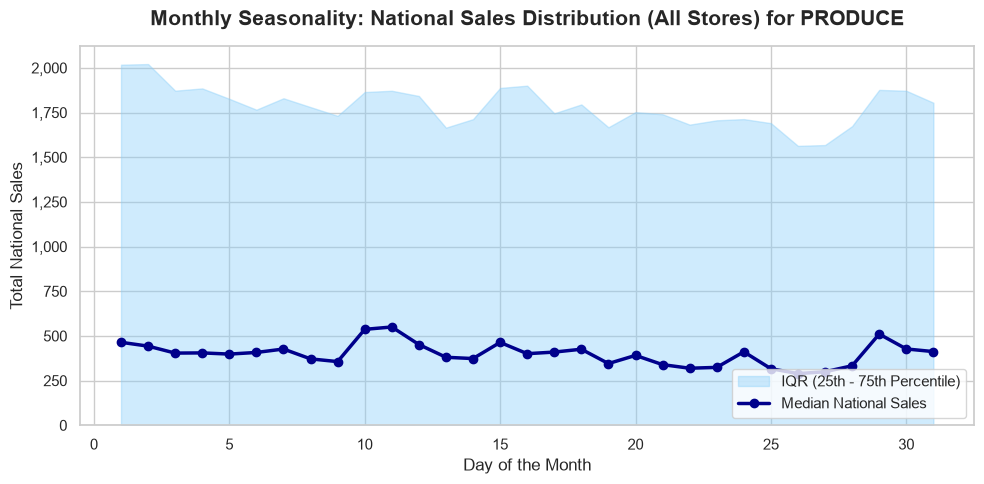

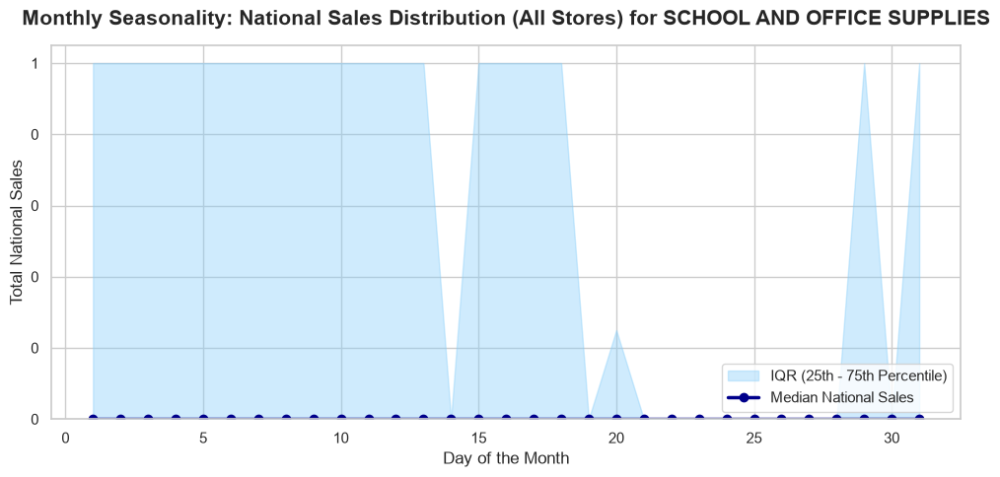

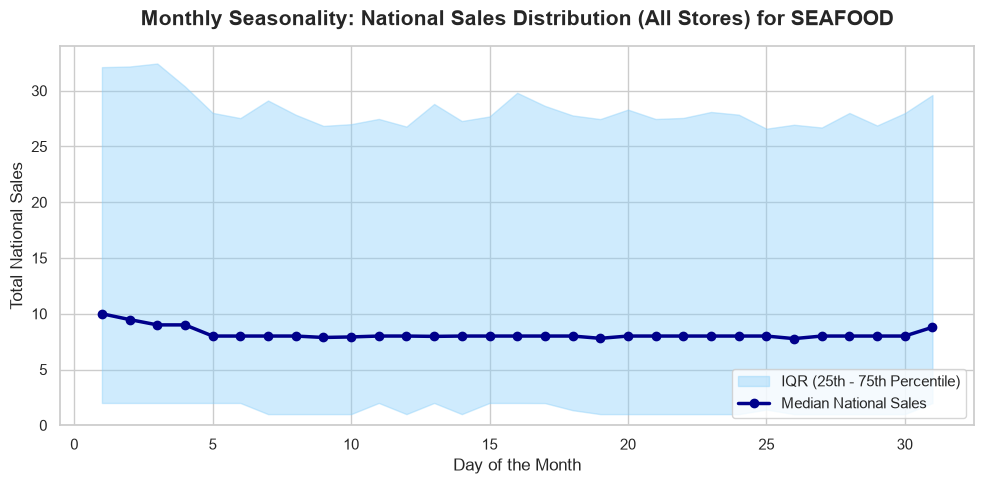

In [211]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

for i in df["family"].unique():
    # df_daily_total = df[(df["is_holiday"]==0) & (df["family"]==i)].groupby(["date"])["sales"].sum().reset_index()
    df_daily_total = df[(df["is_holiday"] == 0) & (df["family"] == i)]

    df_daily_total["day"] = df_daily_total["date"].dt.day

    weekly_stats = (
        df_daily_total.groupby("day")["sales"]
        .agg(
            median="median",
            q25=lambda x: x.quantile(0.25),
            q75=lambda x: x.quantile(0.75),
        )
        .reset_index()
    )

    sns.set_theme(style="whitegrid")
    plt.figure(figsize=(10, 5))

    plt.fill_between(
        weekly_stats["day"],
        weekly_stats["q25"],
        weekly_stats["q75"],
        color="lightskyblue",
        alpha=0.4,
        label="IQR (25th - 75th Percentile)",
    )

    plt.plot(
        weekly_stats["day"],
        weekly_stats["median"],
        color="darkblue",
        linewidth=2.5,
        marker="o",
        markersize=6,
        label="Median National Sales",
    )

    plt.title(
        f"Monthly Seasonality: National Sales Distribution (All Stores) for {i}",
        fontsize=15,
        fontweight="bold",
        pad=15,
    )
    plt.xlabel("Day of the Month", fontsize=12)
    plt.ylabel("Total National Sales", fontsize=12)

    plt.gca().yaxis.set_major_formatter(
        plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x)))
    )
    plt.ylim(bottom=0)

    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.show()

In [173]:
df_daily

,date,sales,is_earthquake_manabi,is_closed,is_drastic_drop,is_commercial_spike,is_regular_holiday,day_type
0,2013-01-19,432459.852021,0,0,0,0,0,Normal Day
1,2013-01-20,461092.386047,0,0,0,0,0,Normal Day
2,2013-01-21,311211.265950,0,0,0,0,0,Normal Day
3,2013-01-22,296214.728983,0,0,0,0,0,Normal Day
4,2013-01-23,283258.453032,0,0,0,0,0,Normal Day
...,...,...,...,...,...,...,...,...
1665,2017-08-11,826373.722022,0,0,0,0,1,Regular Holiday
1666,2017-08-12,792630.535079,0,0,0,0,0,Normal Day
1667,2017-08-13,865639.677471,0,0,0,0,0,Normal Day
1668,2017-08-14,760922.406081,0,0,0,0,0,Normal Day


/var/folders/b9/tbgpz8m52snfk4vhdbmpn1hr0000gn/T/ipykernel_60463/2626344426.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


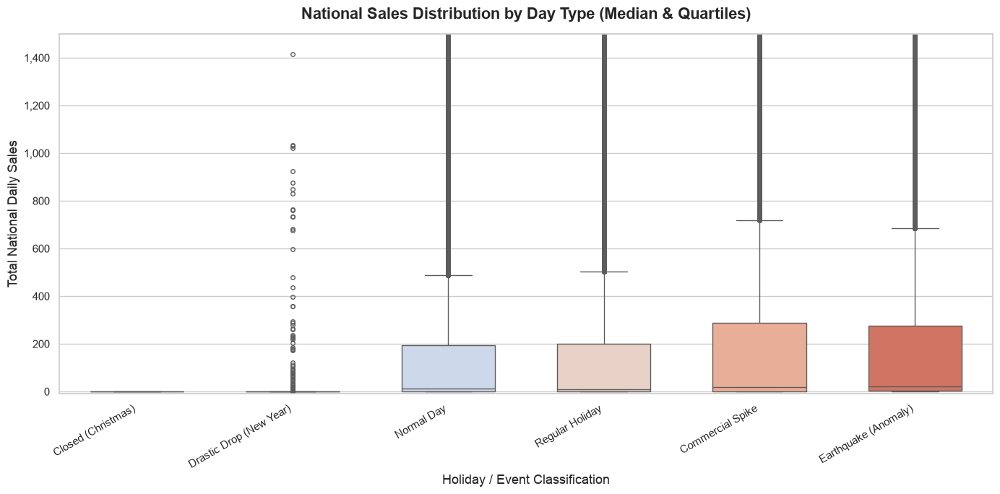

In [188]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 2. PRIMERA AGREGACIÓN: Ventas nacionales por día y mantener las flags
# Usamos 'max' en las columnas 'is_' para que si el día tuvo el evento, se mantenga el 1

# 3. Consolidar los flags en una sola columna categórica para el gráfico
condiciones = [
    df["is_closed"] == 1,
    df["is_drastic_drop"] == 1,
    df["is_earthquake_manabi"] == 1,
    df["is_commercial_spike"] == 1,
    df["is_regular_holiday"] == 1,
]
categorias = [
    "Closed (Christmas)",
    "Drastic Drop (New Year)",
    "Earthquake (Anomaly)",
    "Commercial Spike",
    "Regular Holiday",
]
# Si todas las condiciones son falsas, es un día normal
df["day_type"] = np.select(condiciones, categorias, default="Normal Day")

# 4. Definir un orden lógico para el eje X (de menor a mayor ventas esperadas)
orden_grafico = [
    "Closed (Christmas)",
    "Drastic Drop (New Year)",
    "Normal Day",
    "Regular Holiday",
    "Commercial Spike",
    "Earthquake (Anomaly)",
]

# 5. Configuración y dibujo del gráfico
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 7))

# El boxplot dibuja automáticamente la mediana y los cuartiles (IQR)
sns.boxplot(
    data=df,
    x="day_type",
    y="sales",
    order=orden_grafico,
    palette="coolwarm",  # Un degradado de azul (frío/bajas ventas) a rojo (calor/altas ventas)
    width=0.6,
    fliersize=4,  # Tamaño de los puntos atípicos (outliers)
)

# 6. Estética y formatos
plt.title(
    "National Sales Distribution by Day Type (Median & Quartiles)",
    fontsize=16,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Holiday / Event Classification", fontsize=13)
plt.ylabel("Total National Daily Sales", fontsize=13)

# Formatear el eje Y con comas para los millones
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x)))
)
plt.xticks(rotation=30, ha="right", fontsize=11)
plt.ylim(-10, 1500)

plt.tight_layout()
plt.show()

/var/folders/b9/tbgpz8m52snfk4vhdbmpn1hr0000gn/T/ipykernel_60463/1490164688.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


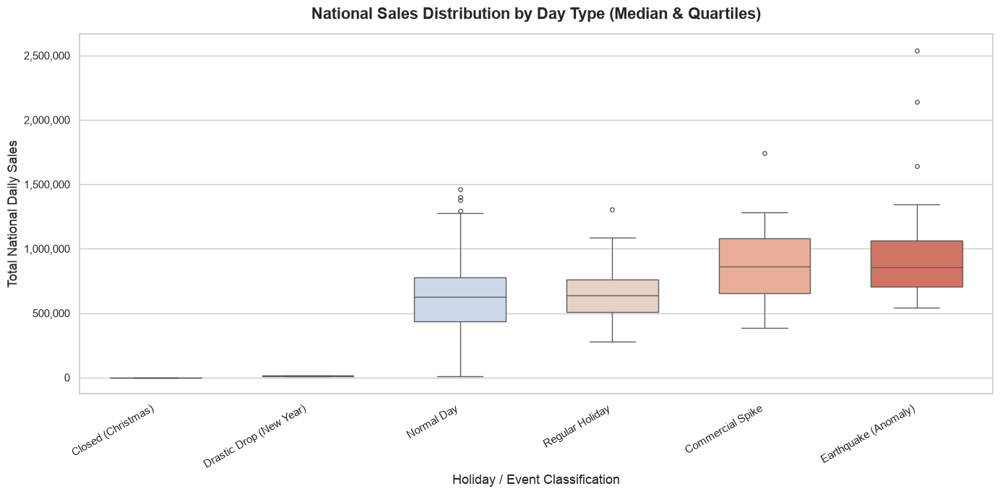

In [172]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Asegurar formato de fecha
df["date"] = pd.to_datetime(df["date"])

# 2. PRIMERA AGREGACIÓN: Ventas nacionales por día y mantener las flags
# Usamos 'max' en las columnas 'is_' para que si el día tuvo el evento, se mantenga el 1
df_daily = (
    df.groupby("date")
    .agg(
        {
            "sales": "sum",
            "is_earthquake_manabi": "max",
            "is_closed": "max",
            "is_drastic_drop": "max",
            "is_commercial_spike": "max",
            "is_regular_holiday": "max",
        }
    )
    .reset_index()
)

# 3. Consolidar los flags en una sola columna categórica para el gráfico
condiciones = [
    df_daily["is_closed"] == 1,
    df_daily["is_drastic_drop"] == 1,
    df_daily["is_earthquake_manabi"] == 1,
    df_daily["is_commercial_spike"] == 1,
    df_daily["is_regular_holiday"] == 1,
]
categorias = [
    "Closed (Christmas)",
    "Drastic Drop (New Year)",
    "Earthquake (Anomaly)",
    "Commercial Spike",
    "Regular Holiday",
]
# Si todas las condiciones son falsas, es un día normal
df_daily["day_type"] = np.select(condiciones, categorias, default="Normal Day")

# 4. Definir un orden lógico para el eje X (de menor a mayor ventas esperadas)
orden_grafico = [
    "Closed (Christmas)",
    "Drastic Drop (New Year)",
    "Normal Day",
    "Regular Holiday",
    "Commercial Spike",
    "Earthquake (Anomaly)",
]

# 5. Configuración y dibujo del gráfico
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 7))

# El boxplot dibuja automáticamente la mediana y los cuartiles (IQR)
sns.boxplot(
    data=df_daily,
    x="day_type",
    y="sales",
    order=orden_grafico,
    palette="coolwarm",  # Un degradado de azul (frío/bajas ventas) a rojo (calor/altas ventas)
    width=0.6,
    fliersize=4,  # Tamaño de los puntos atípicos (outliers)
)

# 6. Estética y formatos
plt.title(
    "National Sales Distribution by Day Type (Median & Quartiles)",
    fontsize=16,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Holiday / Event Classification", fontsize=13)
plt.ylabel("Total National Daily Sales", fontsize=13)

# Formatear el eje Y con comas para los millones
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x)))
)
plt.xticks(rotation=30, ha="right", fontsize=11)

plt.tight_layout()
plt.show()

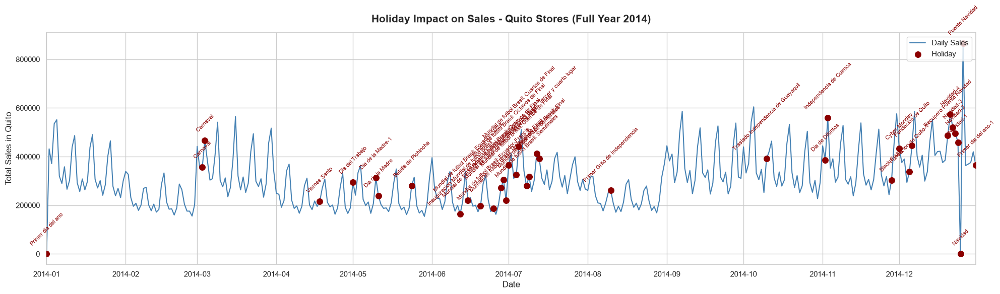

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

YEAR = 2014

# Filtrar solo Quito
df_quito = df[df["city"] == "Quito"].copy()

# 2. AGRUPACIÓN ROBUSTA (Evita duplicados y sumas partidas)
# A) Sumar ventas puramente por fecha
df_daily_sales = df_quito.groupby(["date", "year"])["sales"].sum().reset_index()

# B) Extraer el mapeo de fechas festivas (eliminando duplicados del mismo día)
df_hols_info = df_quito[df_quito["is_holiday"] == 1][
    ["date", "holiday_description", "year"]
].drop_duplicates(subset=["date"])

# C) Unir ambos para tener exactamente 1 fila por día con el total real
df_plot = df_daily_sales.merge(df_hols_info, on=["date", "year"], how="left")
df_plot["is_holiday"] = df_plot["holiday_description"].notna().astype(int)

# 3. Ampliar la serie: Todo el año 2016 (puedes cambiarlo a 2015-2017 si quieres)
df_plot = df_plot[(df_plot["year"] == YEAR)].copy()

# 4. Configuración del gráfico (Más ancho para que quepa todo el año: 20x6)
sns.set_theme(style="whitegrid")
plt.figure(figsize=(20, 6))

# Capa A: La línea continua de ventas
sns.lineplot(
    data=df_plot,
    x="date",
    y="sales",
    color="steelblue",
    linewidth=1.5,
    label="Daily Sales",
)

# Capa B: Los marcadores (puntos rojos)
df_holidays = df_plot[df_plot["is_holiday"] == 1]
plt.scatter(
    df_holidays["date"],
    df_holidays["sales"],
    color="darkred",
    s=70,
    zorder=5,
    label="Holiday",
)

# Capa C: Añadir el texto de la descripción
for _, row in df_holidays.iterrows():
    plt.annotate(
        str(row["holiday_description"]),
        (row["date"], row["sales"]),
        textcoords="offset points",
        xytext=(0, 12),  # Un pelín más alto para separar de la línea
        ha="center",
        fontsize=8,
        color="darkred",
        rotation=45,
        zorder=6,
    )

# 5. Estética y formatos
plt.title(
    f"Holiday Impact on Sales - Quito Stores (Full Year {YEAR})",
    fontsize=15,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Total Sales in Quito", fontsize=12)

# Formatear eje Y y ajustar límites para que no quede espacio vacío a los lados
plt.xlim(df_plot["date"].min(), df_plot["date"].max())
plt.legend(loc="upper right")

plt.tight_layout()
plt.show()

In [ ]:
def prep_train_df(
    df: pd.DataFrame, lags: list[int], drop_lag_nan: bool = True
) -> pd.DataFrame:
    """Preprocesses the main sales dataset by parsing dates, casting types,
    generating temporal and lag features and getting the sales types for each family.
    """

    df = fulfill_sales(df)

    df["date"] = pd.to_datetime(df["date"])

    df["weekday"] = df["date"].dt.day_of_week
    df["month"] = df["date"].dt.month
    df["week"] = df["date"].dt.isocalendar().week
    df["year"] = df["date"].dt.year

    df = prep_train_get_lags(df, lags)

    if drop_lag_nan:
        max_lag = max(lags)
        df = df.dropna(subset=[f"sales_lag{max_lag}"]).reset_index(drop=True)

    # Gets sales types for each family
    is_decimal = df["sales"] % 1 != 0
    family_has_decimals = is_decimal.groupby(df["family"], observed=True).any()
    df["is_int_sales"] = df["family"].map(~family_has_decimals)

    return df

In [ ]:
import pandas as pd
from pathlib import Path
from storesales.preprocessing import prep_train_df, prep_stores_df, prep_holiday_df

REGULAR_HOLIDAY_LIST = [
    "Carnaval",
    "Dia de Difuntos",
    "Independencia de Cuenca",
    "Viernes Santo",
    "Dia del Trabajo",
    "Primer Grito de Independencia",
    "Traslado Primer Grito de Independencia",
    "Batalla de Pichincha",
    "Traslado Batalla de Pichincha",
    "Independencia de Guayaquil",
    "Traslado Independencia de Guayaquil",
    "Puente Navidad",
    "Recupero puente Navidad",
    "Puente Primer dia del ano",
    "Recupero puente primer dia del ano",
    "Puente Dia de Difuntos",
]

COMMERCIAL_SPIKE_LIST = [
    "Black Friday",
    "Cyber Monday",
    "Dia de la Madre",
    "Dia de la Madre-1",
    "Primer dia del ano-1",
]

# Path.cwd() detecta dónde estás. .parent sube un nivel hacia la raíz del proyecto.
BASE_DIR = Path.cwd().parent

# Usamos el operador / de pathlib para unir rutas de forma segura en cualquier sistema operativo (macOS, Windows, etc.)
PATH_HOLIDAYS_DATA = BASE_DIR / "data" / "raw" / "holidays_events.csv"
PATH_SALES_DATA = BASE_DIR / "data" / "raw" / "train.csv"
PATH_STORES_DATA = BASE_DIR / "data" / "raw" / "stores.csv"

# Pandas lee objetos Path nativamente sin necesidad de convertirlos a string
sales = pd.read_csv(PATH_SALES_DATA)
holidays = pd.read_csv(PATH_HOLIDAYS_DATA)
stores = pd.read_csv(PATH_STORES_DATA)

df_sales = prep_train_df(sales, [16, 17, 18])
df_stores = prep_stores_df(stores)
df_holidays = prep_holiday_df(holidays)

In [220]:
df.columns

Index(['store_nbr', 'family', 'date', 'sales', 'onpromotion', 'sales_missing',
       'weekday', 'month', 'week', 'year', 'sales_lag16', 'sales_lag17',
       'sales_lag18', 'is_int_sales', 'city', 'state', 'store_type',
       'store_cluster', 'is_holiday', 'holiday_locale', 'holiday_description',
       'holiday_type', 'is_earthquake_manabi', 'is_closed', 'is_drastic_drop',
       'is_commercial_spike', 'is_regular_holiday'],
      dtype='str')

In [ ]:
def holiday_transfrom_and_join(df: pd.DataFrame, df_holiday_events: pd.DataFrame):

    city_holidays = df_holiday_events[df_holiday_events["locale"] == "Local"]
    national_holidays = df_holiday_events[df_holiday_events["locale"] == "National"]
    regional_holidays = df_holiday_events[df_holiday_events["locale"] == "Regional"]

    df = df.merge(
        city_holidays[["date", "locale_name", "description", "type"]],
        how="left",
        left_on=["date", "city"],
        right_on=["date", "locale_name"],
    )

    df = df.merge(
        regional_holidays[["date", "locale_name", "description", "type"]],
        how="left",
        left_on=["date", "state"],
        right_on=["date", "locale_name"],
    )

    df = df.merge(
        national_holidays[["date", "locale_name", "description", "type"]],
        how="left",
        left_on=["date"],
        right_on=["date"],
    )

    holiday_cols = [col for col in df.columns if col.startswith("locale")]
    description_cols = [col for col in df.columns if col.startswith("description")]
    type_cols = [col for col in df.columns if col.startswith("type")]

    df["is_holiday"] = df[holiday_cols].notna().any(axis=1).astype(int)

    df["holiday_locale"] = (
        df["locale_name_x"].fillna(df["locale_name_y"]).fillna(df["locale_name"])
    )
    df["holiday_description"] = (
        df["description_x"]
        .fillna(df["description_y"])
        .fillna(df["description"])
        .fillna("Normal Day")
    )
    df["holiday_type"] = df["type_x"].fillna(df["type_y"]).fillna(df["type"])

    df = df.drop(columns=holiday_cols + description_cols + type_cols)

    df["is_earthquake_manabi"] = (
        df["holiday_description"]
        .str.startswith("Terremoto Manabi", na=False)
        .astype(int)
    )
    df["is_closed"] = (df["holiday_description"] == "Navidad").astype(int)
    df["is_drastic_drop"] = (df["holiday_description"] == "Primer dia del ano").astype(
        int
    )

    df["is_commercial_spike"] = (
        df["holiday_description"].str.startswith("Navidad", na=False)
        | df["holiday_description"].isin(COMMERCIAL_SPIKE_LIST)
    ).astype(int)

    df["is_regular_holiday"] = (
        df["holiday_description"].isin(REGULAR_HOLIDAY_LIST)
        | df["holiday_description"].str.contains("futbol Brasil", na=False, case=False)
    ).astype(int)

    return df


def prep_joins(
    df_sales: pd.DataFrame,
    df_stores: pd.DataFrame,
    df_holiday_events: pd.DataFrame,
    # df_oil: pd.DataFrame,
    # df_transactions: pd.DataFrame,
) -> pd.DataFrame:
    """Joins all the datasets"""

    # Joins the sales history dataset with the stores dataset
    df = df_sales.merge(df_stores, how="left", on=["store_nbr"])

    df = holiday_transfrom_and_join(df, df_holiday_events)

    # Joins with oil dataset
    df = df.merge(df_oil, on="date", how="left")

    # Joins with transactions dataset
    df = df.merge(df_transactions, how="left", on=["store_nbr", "date"])

    df = df.sort_values(["family", "store_nbr", "date"])

    return df

In [218]:
df = prep_joins(df_sales, df_stores, holidays)

In [219]:
df

,store_nbr,family,date,sales,onpromotion,sales_missing,weekday,month,week,year,...,store_cluster,is_holiday,holiday_locale,holiday_description,holiday_type,is_earthquake_manabi,is_closed,is_drastic_drop,is_commercial_spike,is_regular_holiday
0,1,AUTOMOTIVE,2013-01-19,5.0,0.0,0,5,1,3,2013,...,13,0,NaN,Normal Day,NaN,0,0,0,0,0
1,1,AUTOMOTIVE,2013-01-20,3.0,0.0,0,6,1,3,2013,...,13,0,NaN,Normal Day,NaN,0,0,0,0,0
2,1,AUTOMOTIVE,2013-01-21,1.0,0.0,0,0,1,4,2013,...,13,0,NaN,Normal Day,NaN,0,0,0,0,0
3,1,AUTOMOTIVE,2013-01-22,1.0,0.0,0,1,1,4,2013,...,13,0,NaN,Normal Day,NaN,0,0,0,0,0
4,1,AUTOMOTIVE,2013-01-23,3.0,0.0,0,2,1,4,2013,...,13,0,NaN,Normal Day,NaN,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2983327,54,SEAFOOD,2017-08-11,0.0,0.0,0,4,8,32,2017,...,3,1,Ecuador,Traslado Primer Grito de Independencia,Transfer,0,0,0,0,1
2983328,54,SEAFOOD,2017-08-12,1.0,1.0,0,5,8,32,2017,...,3,0,NaN,Normal Day,NaN,0,0,0,0,0
2983329,54,SEAFOOD,2017-08-13,2.0,0.0,0,6,8,32,2017,...,3,0,NaN,Normal Day,NaN,0,0,0,0,0
2983330,54,SEAFOOD,2017-08-14,0.0,0.0,0,0,8,33,2017,...,3,0,NaN,Normal Day,NaN,0,0,0,0,0


In [222]:
df.columns

Index(['store_nbr', 'family', 'date', 'sales', 'onpromotion', 'sales_missing',
       'weekday', 'month', 'week', 'year', 'sales_lag16', 'sales_lag17',
       'sales_lag18', 'is_int_sales', 'city', 'state', 'store_type',
       'store_cluster', 'is_holiday', 'holiday_locale', 'holiday_description',
       'holiday_type', 'is_earthquake_manabi', 'is_closed', 'is_drastic_drop',
       'is_commercial_spike', 'is_regular_holiday'],
      dtype='str')